# GDP Analysis (2000–2022)

This notebook loads, cleans and plots annual GDP for seven economies (United States, China, Japan, Germany, United Kingdom, Brazil and Switzerland) from 2000 to 2022. GDP is in billions of current US dollars.

All the logic lives in the `fed` package, and this notebook only imports and calls it:
- `fed.data`: `load_data()` and `clean_data()` load the CSV and reshape it into long format
- `fed.plot_utils`: `plot_gdp_trends()` plots GDP over time

In [1]:
from fed.data import load_data, clean_data
from fed.plot_utils import plot_gdp_trends

## 1. Load and clean the data

In [2]:
df = clean_data(load_data())
df.head()

,Country Name,Country Code,Year,GDP
0,United States,USA,2000,10252
1,China,CHN,2000,1211
2,Japan,JPN,2000,4968
3,Germany,DEU,2000,1948
4,United Kingdom,GBR,2000,1663


In [3]:
print(df.shape)
print(sorted(df["Country Name"].unique()))
print(df["Year"].min(), "to", df["Year"].max())

(161, 4)
['Brazil', 'China', 'Germany', 'Japan', 'Switzerland', 'United Kingdom', 'United States']
2000 to 2022


## 2. GDP over time

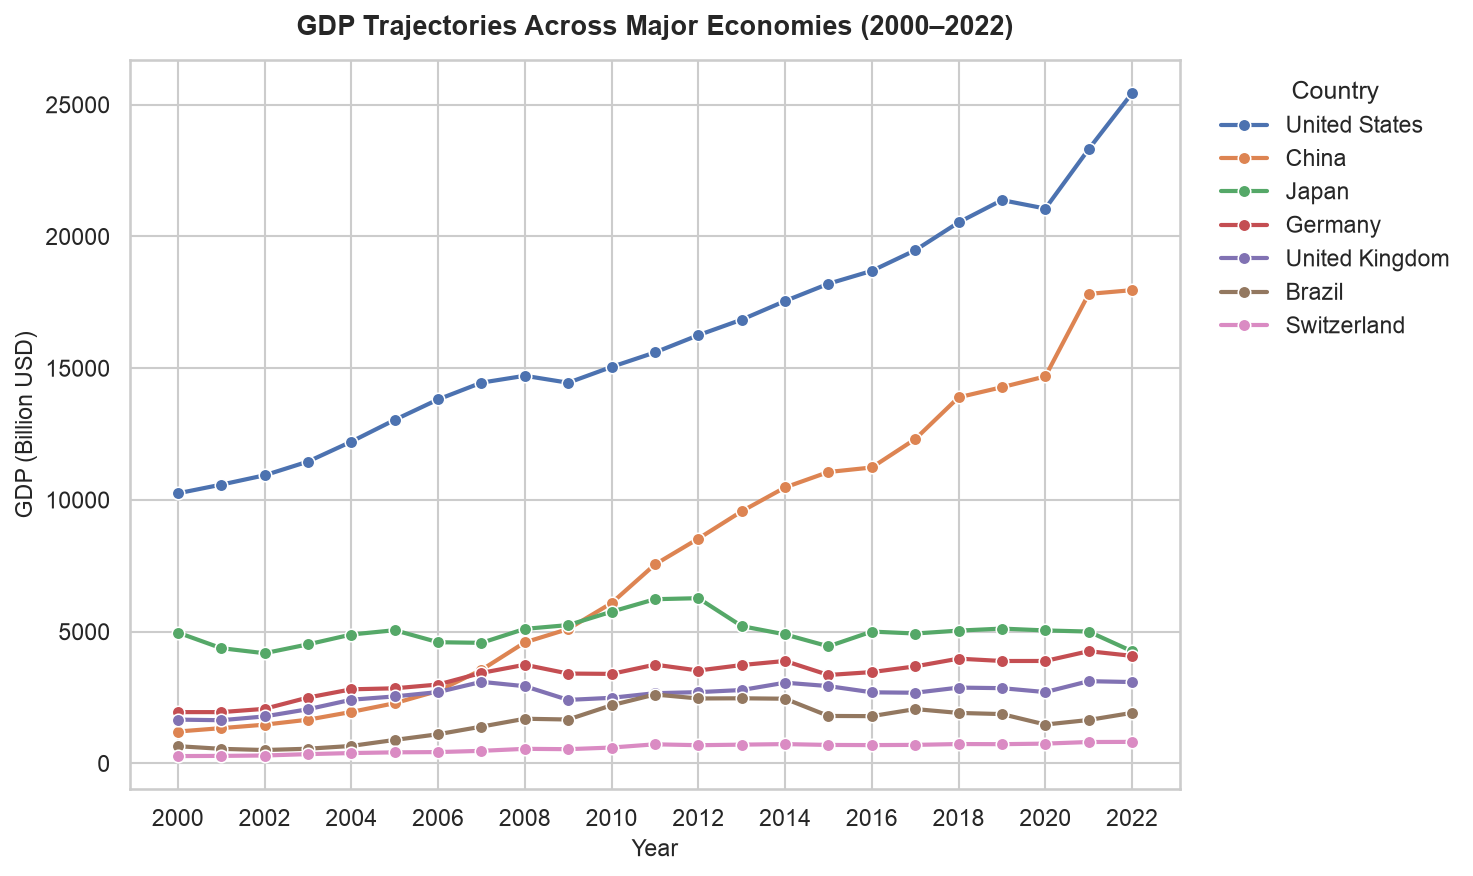

In [4]:
fig = plot_gdp_trends(df)

The United States and China are much larger than the other economies, which squashes the rest at the bottom of the chart. Here are the other five on their own:

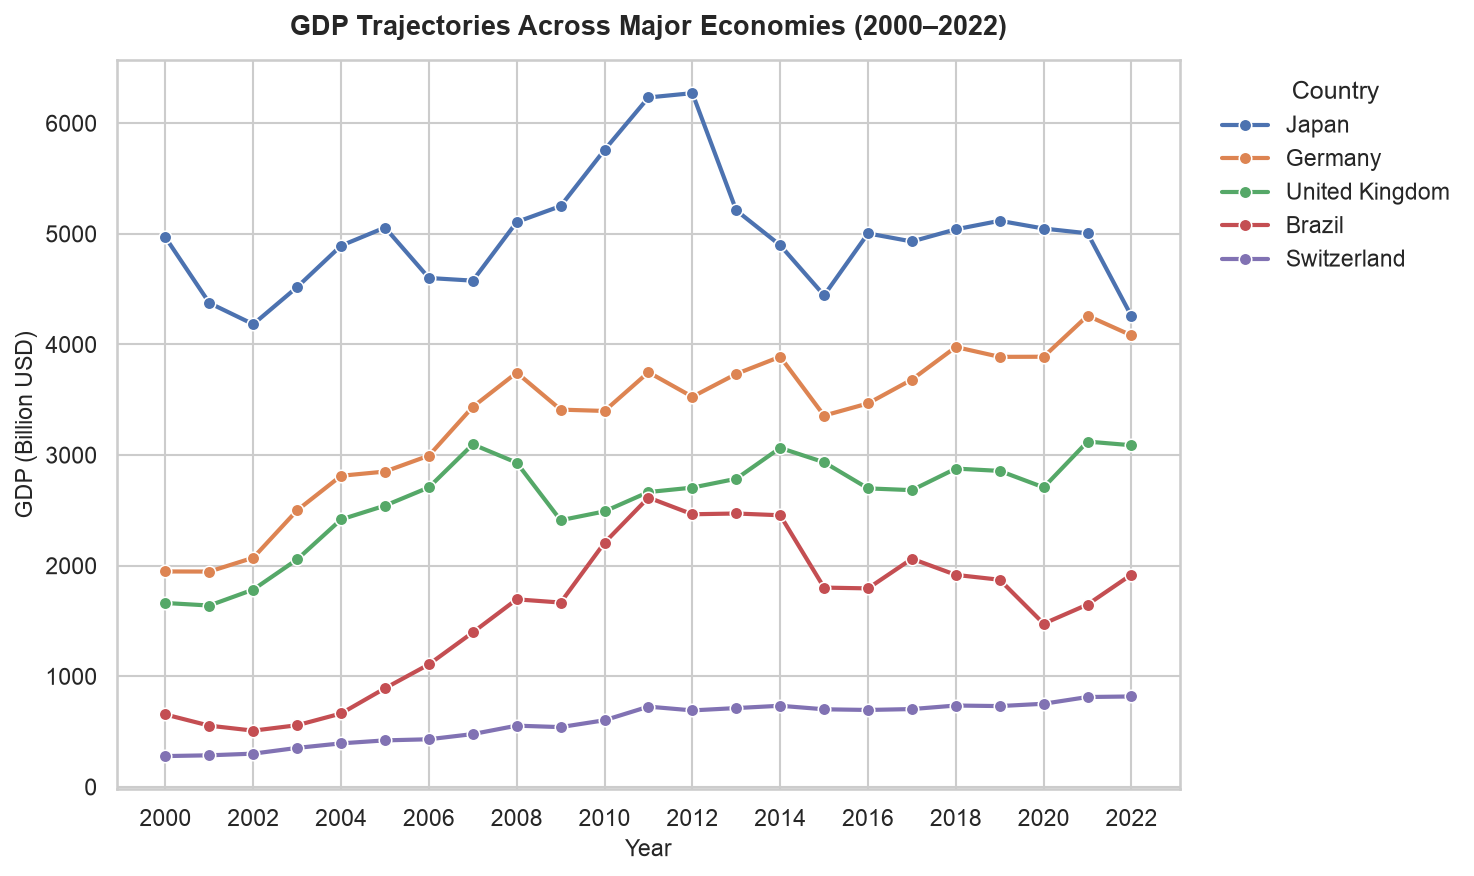

In [5]:
fig = plot_gdp_trends(
    df, countries=["Japan", "Germany", "United Kingdom", "Brazil", "Switzerland"]
)

## 3. GDP in key years

In [6]:
df.pivot(index="Country Name", columns="Year", values="GDP")[[2000, 2008, 2009, 2019, 2020, 2022]]

Year,2000,2008,2009,2019,2020,2022
Country Name,,,,,,
Brazil,655,1696,1667,1873,1476,1920
China,1211,4594,5102,14280,14688,17963
Germany,1948,3745,3411,3888,3889,4082
Japan,4968,5107,5251,5118,5048,4256
Switzerland,279,554,541,731,752,818
United Kingdom,1663,2931,2411,2857,2708,3089
United States,10252,14713,14449,21381,21060,25440


## 4. How GDP developed, 2000–2022

- **United States:** the largest economy throughout, growing from about 10.3 to 25.4 trillion USD (×2.5). Growth was steady, with small dips in 2009 (global financial crisis) and 2020 (COVID-19), followed by a strong rebound in 2021–2022.
- **China:** by far the fastest growth. Its GDP was almost 15 times larger in 2022 than in 2000 (about 13% a year). It overtook Japan in 2010 and rose from about 12% of US GDP in 2000 to about 71% in 2022.
- **Japan:** the only economy that was smaller in 2022 than in 2000. It peaked in 2012 at about 6.3 trillion USD and then fell back, partly because the yen weakened against the dollar.
- **Germany and the United Kingdom:** both roughly doubled, with clear drops after the 2008–09 financial crisis (the UK fell from about 2.9 to 2.4 trillion USD) and smaller swings since then.
- **Brazil:** the most volatile. GDP quadrupled to a peak of about 2.6 trillion USD in 2011, then fell sharply in the mid-2010s and again in 2020, ending at about 1.9 trillion USD.
- **Switzerland:** the smallest economy here, but it grew steadily and almost tripled (×2.9).

**Note:** these are nominal GDP figures in current US dollars, so exchange-rate movements matter as well as real growth. For example, part of Japan's fall reflects a weaker yen rather than a shrinking economy.